# Chapter 5: Linear Models and Regularization

This notebook covers Chapter 5 of *scikit-learn Cookbook* (3rd Edition, Packt). Linear models predict a target as a weighted sum of the features. They are fast, interpretable, and a strong baseline. When there are many or correlated features, plain linear regression can overfit, so **regularization** adds a penalty on the size of the coefficients.

**Topics covered:**
- Ordinary least squares linear regression
- Polynomial regression and overfitting
- Ridge regression (L2 penalty)
- Lasso regression (L1 penalty) and feature selection
- ElasticNet (L1 + L2)
- Choosing the penalty strength with cross-validation
- Stochastic Gradient Descent (SGD) regression

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import (LinearRegression, Ridge, Lasso, ElasticNet,
                                  RidgeCV, LassoCV, ElasticNetCV, SGDRegressor)
from sklearn.metrics import mean_squared_error, r2_score

## 1. Ordinary Least Squares (OLS)

Linear regression models the target as

$$\hat{y} = b + w_1 x_1 + w_2 x_2 + \dots + w_p x_p$$

and chooses the weights that minimize the **sum of squared errors**:

$$\min_{\mathbf{w}, b} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2$$

Performance is measured with **RMSE** (average prediction error in the target's units) and **$R^2$** (share of variance explained). The **diabetes** dataset (442 patients, 10 features) is used, with the target being disease progression after one year.

In [2]:
diab = load_diabetes(as_frame=True)
X, y = diab.data, diab.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

def evaluate(model, name):
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    rmse = mean_squared_error(y_test, pred) ** 0.5
    print(f'{name:>22}: test RMSE = {rmse:6.2f}, R2 = {r2_score(y_test, pred):.3f}')
    return model

ols = evaluate(make_pipeline(StandardScaler(), LinearRegression()), 'Linear regression')
pd.Series(ols[-1].coef_, index=X.columns).round(2)

     Linear regression: test RMSE =  53.37, R2 = 0.485


age     2.22
sex   -11.51
bmi    25.08
bp     18.25
s1    -44.14
s2     24.51
s3      5.50
s4     13.01
s5     33.38
s6      1.25
dtype: float64

Because the features were standardized, the coefficients can be compared directly: features with larger absolute coefficients (such as `bmi` and `s5`) have a stronger effect on the predicted disease progression.

## 2. Polynomial Regression and Overfitting

Adding polynomial and interaction terms lets a linear model fit curved relationships. But with many terms, the model can **overfit**: it fits the training data very well and new data poorly.

In [3]:
for degree in [1, 2, 3]:
    model = make_pipeline(PolynomialFeatures(degree), StandardScaler(), LinearRegression())
    model.fit(X_train, y_train)
    n_feat = model[0].n_output_features_
    print(f'degree {degree}: {n_feat:>3} features, '
          f'train R2 = {model.score(X_train, y_train):.3f}, '
          f'test R2 = {model.score(X_test, y_test):.3f}')

degree 1:  11 features, train R2 = 0.519, test R2 = 0.485
degree 2:  66 features, train R2 = 0.605, test R2 = 0.424
degree 3: 286 features, train R2 = 0.909, test R2 = -38.528


As the degree increases, the number of features grows quickly and the training $R^2$ keeps rising, but the test $R^2$ drops. This gap is the signature of overfitting, and it is exactly the problem regularization is designed to solve.

## 3. Ridge Regression (L2 Penalty)

**Ridge** adds the sum of squared coefficients to the loss:

$$\min_{\mathbf{w}} \sum_i (y_i - \hat{y}_i)^2 + \alpha \sum_j w_j^2$$

The penalty strength $\alpha$ controls how much the coefficients are **shrunk toward zero**. Ridge keeps all features but makes their weights smaller and more stable, which helps especially when features are correlated (**multicollinearity**). Features should be scaled so the penalty treats them fairly.

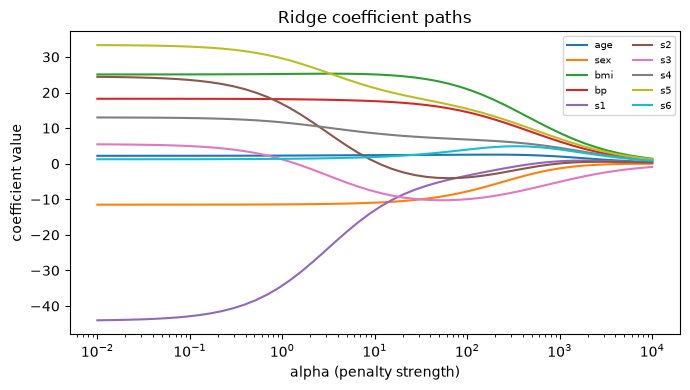

      Ridge (alpha=10): test RMSE =  53.20, R2 = 0.488


In [4]:
alphas = np.logspace(-2, 4, 50)
coefs = [Ridge(alpha=a).fit(StandardScaler().fit_transform(X_train), y_train).coef_
         for a in alphas]

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(alphas, coefs)
ax.set_xscale('log')
ax.set_xlabel('alpha (penalty strength)')
ax.set_ylabel('coefficient value')
ax.set_title('Ridge coefficient paths')
ax.legend(X.columns, fontsize=7, ncol=2)
plt.tight_layout()
plt.show()

ridge = evaluate(make_pipeline(StandardScaler(), Ridge(alpha=10)), 'Ridge (alpha=10)')

The coefficient paths show that as $\alpha$ increases, all coefficients shrink smoothly toward zero but never become exactly zero. A moderate $\alpha$ gives performance similar to or better than plain linear regression, with more stable coefficients.

## 4. Lasso Regression (L1 Penalty)

**Lasso** uses the sum of absolute coefficients as the penalty:

$$\min_{\mathbf{w}} \frac{1}{2n}\sum_i (y_i - \hat{y}_i)^2 + \alpha \sum_j |w_j|$$

Unlike Ridge, the L1 penalty can set coefficients **exactly to zero**, so Lasso performs **automatic feature selection** and produces simpler, more interpretable models.

In [5]:
for alpha in [0.1, 1, 5]:
    lasso = make_pipeline(StandardScaler(), Lasso(alpha=alpha)).fit(X_train, y_train)
    coef = lasso[-1].coef_
    kept = list(X.columns[coef != 0])
    print(f'alpha={alpha:>3}: test R2 = {lasso.score(X_test, y_test):.3f}, '
          f'{len(kept)} features kept: {kept}')

alpha=0.1: test R2 = 0.487, 9 features kept: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's4', 's5', 's6']
alpha=  1: test R2 = 0.496, 9 features kept: ['age', 'sex', 'bmi', 'bp', 's1', 's3', 's4', 's5', 's6']
alpha=  5: test R2 = 0.496, 5 features kept: ['sex', 'bmi', 'bp', 's3', 's5']


As $\alpha$ grows, Lasso removes more features by setting their coefficients to zero, while the most important ones (such as `bmi` and `s5`) remain. A small loss in accuracy can buy a much simpler model.

## 5. ElasticNet (L1 + L2)

**ElasticNet** combines both penalties:

$$\alpha \left( \rho \sum_j |w_j| + \frac{1 - \rho}{2} \sum_j w_j^2 \right)$$

where `l1_ratio` ($\rho$) sets the balance: 1 is pure Lasso and 0 is pure Ridge. It selects features like Lasso but behaves better when features are strongly correlated, since Lasso tends to pick one feature from a correlated group arbitrarily.

In [6]:
enet = evaluate(make_pipeline(StandardScaler(), ElasticNet(alpha=0.5, l1_ratio=0.5)),
                'ElasticNet')
print('Non-zero coefficients:', int((enet[-1].coef_ != 0).sum()), 'of', X.shape[1])

            ElasticNet: test RMSE =  52.98, R2 = 0.492
Non-zero coefficients: 10 of 10


## 6. Choosing the Penalty with Cross-Validation

The best $\alpha$ is chosen with cross-validation. scikit-learn provides `RidgeCV`, `LassoCV`, and `ElasticNetCV`, which search over many values efficiently and pick the best one automatically.

In [7]:
ridge_cv = evaluate(make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-3, 3, 50))),
                    'RidgeCV')
lasso_cv = evaluate(make_pipeline(StandardScaler(), LassoCV(cv=5, random_state=42)),
                    'LassoCV')
enet_cv = evaluate(make_pipeline(StandardScaler(),
                                 ElasticNetCV(l1_ratio=[0.1, 0.5, 0.9], cv=5, random_state=42)),
                   'ElasticNetCV')

print('\nBest alpha (Ridge):', round(ridge_cv[-1].alpha_, 3))
print('Best alpha (Lasso):', round(lasso_cv[-1].alpha_, 3))
print('Best alpha / l1_ratio (ElasticNet):', round(enet_cv[-1].alpha_, 3), '/', enet_cv[-1].l1_ratio_)

               RidgeCV: test RMSE =  53.30, R2 = 0.486
               LassoCV: test RMSE =  53.28, R2 = 0.487
          ElasticNetCV: test RMSE =  53.27, R2 = 0.487

Best alpha (Ridge): 1.526
Best alpha (Lasso): 0.106
Best alpha / l1_ratio (ElasticNet): 0.051 / 0.9


The cross-validated models find their own penalty strength and reach test performance close to the best manual choices, without guessing. This is the recommended way to use regularized models in practice.

## 7. Stochastic Gradient Descent (SGD) Regression

For very large datasets, solving the least-squares problem directly becomes expensive. **SGDRegressor** instead updates the weights step by step, using one sample (or a small batch) at a time:

$$\mathbf{w} \leftarrow \mathbf{w} - \eta \, \nabla L(\mathbf{w})$$

where $\eta$ is the learning rate. It supports the same penalties (`'l2'`, `'l1'`, `'elasticnet'`) and can learn incrementally with `partial_fit()`. SGD is very sensitive to feature scaling.

In [8]:
sgd = evaluate(make_pipeline(StandardScaler(),
                             SGDRegressor(penalty='l2', alpha=0.01, max_iter=5000,
                                          random_state=42)),
               'SGDRegressor')

          SGDRegressor: test RMSE =  53.34, R2 = 0.485


SGD reaches performance similar to the exact linear models on this small dataset. Its real advantage appears with millions of samples, where it scales much better than methods that use all data at once.

## Chapter Summary

- **Linear regression** minimizes squared errors and gives interpretable coefficients, especially after standardizing features.
- Adding **polynomial features** increases flexibility but can cause **overfitting**: training scores rise while test scores fall.
- **Ridge (L2)** shrinks all coefficients toward zero and stabilizes models with correlated features.
- **Lasso (L1)** can set coefficients exactly to zero, performing automatic feature selection.
- **ElasticNet** combines L1 and L2, balancing selection and stability.
- The penalty strength $\alpha$ should be chosen with cross-validation, using `RidgeCV`, `LassoCV`, or `ElasticNetCV`.
- **SGDRegressor** trains linear models incrementally and scales to very large datasets.
- Scaling is essential for regularized and SGD-based models.